In [1]:
# ======================================================================
# CLEAN DUBLIN PPR: one ML-ready table, one row per Dublin property sale
# ======================================================================
# Input:  just_dublin_dataset\just_dublin_processed_dataset\ppr\ppr_dublin.csv
# Output: just_dublin_dataset\Just_dublin_clean_dataset\ppr\ppr_dublin_clean.csv
#
# Same cleaning as the national PPR notebook, for Dublin only, keeping the
# location columns:
#   nation, province, county, local_authority (empty for PPR), dublin_district
#
# What this table is for (Student 3 + group model):
#   - Isolation Forest (unusual sales)   -> price, district, quarter, property type
#   - temporal analysis                  -> district x quarter median prices
#   - Polynomial regression              -> target: log_price
#   - Logistic regression                -> target: not_full_market_price
#
# Rules: unusual prices are only FLAGGED, not deleted; do NOT fill missing
# values, scale or encode here.
#
# Needs the Dublin processed notebooks (00 and 03) to be run first.
# ======================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

pd.set_option('display.max_columns', None)

base = r'C:\Users\LENOVO\OneDrive\OneDrive - National College of Ireland\Machine_learning_Project'

ppr_file     = base + r'\just_dublin_dataset\just_dublin_processed_dataset\ppr\ppr_dublin.csv'
dublin_clean = base + r'\just_dublin_dataset\Just_dublin_clean_dataset'

In [2]:
ppr = pd.read_csv(ppr_file, low_memory=False)

print(ppr.shape)
ppr.head(3)

(106619, 19)


,sale_date,address,county,eircode,price,not_full_market_price,vat_exclusive,property_description,property_size,price_incl_vat,year,quarter,eircode_area,dublin_district,district_id,county_id,province,nation,local_authority
0,2021-01-01,"APT 15, SANDON COVE, CASTLE AVE DUBLIN 3",Dublin,D03RY60,295000.0,No,No,Second-Hand Dwelling house /Apartment,NaN,295000.0,2021,2021Q1,D03,Dublin 3,3,6,Leinster,Ireland,NaN
1,2021-01-01,"APT 32, DANES COURT, CLONTARF RD DUBLIN 3",Dublin,D03W300,310000.0,No,No,Second-Hand Dwelling house /Apartment,NaN,310000.0,2021,2021Q1,D03,Dublin 3,3,6,Leinster,Ireland,NaN
2,2021-01-03,"16 BURLEIGH COURT, BURLINGTON ROAD, DUBLIN 4",Dublin,NaN,450000.0,No,No,Second-Hand Dwelling house /Apartment,NaN,450000.0,2021,2021Q1,NaN,Dublin 4,4,6,Leinster,Ireland,NaN


In [3]:
# Each sale gets its own id, so it can be found again after joins and
# so flagged sales (e.g. from Isolation Forest) can be traced back.

ppr.insert(0, 'sale_id', range(1, len(ppr) + 1))

# Removing extra spaces from text, and turning blank text into missing
for col in ['address', 'county', 'eircode', 'not_full_market_price',
            'vat_exclusive', 'property_description']:
    ppr[col] = ppr[col].str.strip()
    ppr[col] = ppr[col].replace('', np.nan)

ppr['sale_date'] = pd.to_datetime(ppr['sale_date'])
print(ppr['sale_date'].min(), 'to', ppr['sale_date'].max())

2021-01-01 00:00:00 to 2026-10-09 00:00:00


In [4]:
# Location check: every sale should have a district
# (a real one, or 'Dublin (no district)' for places like Swords or Blackrock).

print('Rows without a district:', ppr['dublin_district'].isnull().sum())   # should be 0
print(ppr['dublin_district'].value_counts())

Rows without a district: 0
dublin_district
Dublin (no district)    35851
Dublin 15                7820
Dublin 24                5336
Dublin 18                5071
Dublin 8                 4350
Dublin 4                 4245
Dublin 7                 3778
Dublin 9                 3743
Dublin 13                3703
Dublin 12                3623
Dublin 3                 3307
Dublin 11                3290
Dublin 14                3203
Dublin 16                2981
Dublin 6                 2890
Dublin 22                2887
Dublin 5                 2797
Dublin 1                 2108
Dublin 6W                1734
Dublin 2                 1395
Dublin 10                 920
Dublin 17                 848
Dublin 20                 739
Name: count, dtype: int64


In [5]:
# Property type: New or Second-Hand.
# A handful of rows are written in Irish:
#   'Teach/Árasán Cónaithe Nua'      = new home
#   'Teach/Árasán Cónaithe Atháimhe' = second-hand home

print(ppr['property_description'].value_counts())

ppr['property_type'] = 'Second-Hand'
ppr.loc[ppr['property_description'].str.contains('New'), 'property_type'] = 'New'
ppr.loc[ppr['property_description'].str.contains('Nua'), 'property_type'] = 'New'

print()
print(ppr['property_type'].value_counts())

property_description
Second-Hand Dwelling house /Apartment    87753
New Dwelling house /Apartment            18860
Teach/Árasán Cónaithe Atháimhe               6
Name: count, dtype: int64

property_type
Second-Hand    87759
New            18860
Name: count, dtype: int64


In [6]:
# Yes / No columns -> 1 / 0

ppr['not_full_market_price'] = ppr['not_full_market_price'].map({'Yes': 1, 'No': 0})
ppr['vat_exclusive'] = ppr['vat_exclusive'].map({'Yes': 1, 'No': 0})

print(ppr['not_full_market_price'].value_counts(dropna=False))
print(ppr['vat_exclusive'].value_counts(dropna=False))

not_full_market_price
0    102092
1      4527
Name: count, dtype: int64
vat_exclusive
0    88074
1    18545
Name: count, dtype: int64


In [7]:
# Logistic regression target check: how rare are 'not full market price' sales?
# (imbalanced -> class weights / stratification at the modelling stage)

print(ppr['not_full_market_price'].value_counts(normalize=True).round(3))

not_full_market_price
0    0.958
1    0.042
Name: proportion, dtype: float64


In [8]:
# Price: keeping the recorded price and the VAT-adjusted price (made in the
# processed notebook). The model target is the log of the VAT-adjusted price,
# because prices are very skewed and the proposal uses log price.

ppr = ppr.rename(columns={'price': 'price_recorded'})
ppr['log_price'] = np.log(ppr['price_incl_vat'])

print(ppr[['price_recorded', 'price_incl_vat', 'log_price']].describe().round(2))

       price_recorded  price_incl_vat  log_price
count    1.066190e+05    1.066190e+05  106619.00
mean     6.343734e+05    6.559062e+05      13.05
std      2.846189e+06    3.098181e+06       0.61
min      5.500000e+03    5.500000e+03       8.61
25%      3.300000e+05    3.350000e+05      12.72
50%      4.310000e+05    4.500000e+05      13.02
75%      6.000000e+05    6.150000e+05      13.33
max      2.517694e+08    2.857582e+08      19.47


In [9]:
# Unusual prices: using the IQR rule on log price (same idea as the outlier
# notebook from class). These are only FLAGGED, not removed.
# The limits are worked out on Dublin prices only, so they are higher than
# the national ones.
# A flagged price is not automatically wrong: some are real (expensive Dublin
# homes, cheap rural cottages), others are bulk sales (a whole block of
# apartments for one price) or family transfers. The proposal says unusual
# sales should be looked at, not deleted.

q1 = ppr['log_price'].quantile(0.25)
q3 = ppr['log_price'].quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

ppr['is_extreme_price'] = 0
ppr.loc[(ppr['log_price'] < lower) | (ppr['log_price'] > upper), 'is_extreme_price'] = 1

print('Lower limit: EUR', round(np.exp(lower)))
print('Upper limit: EUR', round(np.exp(upper)))
print('Flagged sales:', ppr['is_extreme_price'].sum(),
      '(', round(ppr['is_extreme_price'].mean() * 100, 1), '% )')

Lower limit: EUR 134679
Upper limit: EUR 1529750
Flagged sales: 4885 ( 4.6 % )


In [10]:
# How the flag relates to 'not full market price' (many cheap sales are
# family transfers, which is what the logistic regression is about)

pd.crosstab(ppr['is_extreme_price'], ppr['not_full_market_price'], normalize='index').round(3)

not_full_market_price,0,1
is_extreme_price,,
0,0.964,0.036
1,0.829,0.171


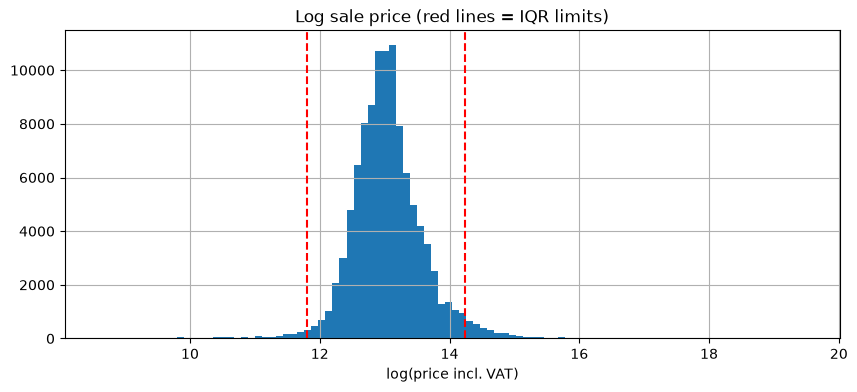

In [11]:
# Log price distribution with the flag limits

plt.figure(figsize=(10, 4))
ppr['log_price'].hist(bins=100)
plt.axvline(lower, color='red', linestyle='--')
plt.axvline(upper, color='red', linestyle='--')
plt.title('Log sale price (red lines = IQR limits)')
plt.xlabel('log(price incl. VAT)')
plt.show()

In [12]:
# Eircode: the full code points at one exact home, so it is not kept.
# The area code (first 3 characters, e.g. 'D12' or 'K67' for Swords) was
# already made in the processed notebook and is kept as eircode_area.

print('Missing Eircode area:', round(ppr['eircode_area'].isnull().mean() * 100, 1), '%')
print(ppr['eircode_area'].nunique(), 'Eircode areas')

Missing Eircode area: 21.2 %
88 Eircode areas


In [13]:
# Choosing the columns for the clean table.
# Left out on purpose:
#   eircode               -> identifies one home (area code kept instead)
#   property_size         -> 100% empty since 2021
#   property_description  -> replaced by property_type
# The address is kept only to spot repeat sales of the same home; it is not
# a model input.

keep = ['sale_id', 'sale_date', 'year', 'quarter',
        'nation', 'province', 'county', 'county_id', 'local_authority',
        'dublin_district', 'district_id', 'eircode_area', 'address',
        'property_type', 'vat_exclusive',
        'price_recorded', 'price_incl_vat', 'log_price',
        'not_full_market_price', 'is_extreme_price']

ppr_clean = ppr[keep]

print(ppr_clean.shape)
ppr_clean.head()

(106619, 20)


,sale_id,sale_date,year,quarter,nation,province,county,county_id,local_authority,dublin_district,district_id,eircode_area,address,property_type,vat_exclusive,price_recorded,price_incl_vat,log_price,not_full_market_price,is_extreme_price
0,1,2021-01-01,2021,2021Q1,Ireland,Leinster,Dublin,6,NaN,Dublin 3,3,D03,"APT 15, SANDON COVE, CASTLE AVE DUBLIN 3",Second-Hand,0,295000.0,295000.000,12.594731,0,0
1,2,2021-01-01,2021,2021Q1,Ireland,Leinster,Dublin,6,NaN,Dublin 3,3,D03,"APT 32, DANES COURT, CLONTARF RD DUBLIN 3",Second-Hand,0,310000.0,310000.000,12.644328,0,0
2,3,2021-01-03,2021,2021Q1,Ireland,Leinster,Dublin,6,NaN,Dublin 4,4,NaN,"16 BURLEIGH COURT, BURLINGTON ROAD, DUBLIN 4",Second-Hand,0,450000.0,450000.000,13.017003,0,0
3,4,2021-01-04,2021,2021Q1,Ireland,Leinster,Dublin,6,NaN,Dublin (no district),23,NaN,"12 Oileain Na Cranoige.Cranogue Isl, Balbutche...",New,1,192951.0,218999.385,12.296824,0,0
4,5,2021-01-04,2021,2021Q1,Ireland,Leinster,Dublin,6,NaN,Dublin (no district),23,NaN,"17 Belltree Lane, Beltree, Clonggriffin",New,1,343612.0,389999.620,12.873901,0,0


In [14]:
# Missing values left (% per column)

missing = (ppr_clean.isnull().mean() * 100).round(1)
missing[missing > 0]

local_authority    100.0
eircode_area        21.2
dtype: float64

In [15]:
ppr_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 106619 entries, 0 to 106618
Data columns (total 20 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   sale_id                106619 non-null  int64         
 1   sale_date              106619 non-null  datetime64[us]
 2   year                   106619 non-null  int64         
 3   quarter                106619 non-null  str           
 4   nation                 106619 non-null  str           
 5   province               106619 non-null  str           
 6   county                 106619 non-null  str           
 7   county_id              106619 non-null  int64         
 8   local_authority        0 non-null       float64       
 9   dublin_district        106619 non-null  str           
 10  district_id            106619 non-null  int64         
 11  eircode_area           84067 non-null   str           
 12  address                106619 non-null  str           


In [16]:
# Saving the clean Dublin PPR table.

save_folder = dublin_clean + r'\ppr'
os.makedirs(save_folder, exist_ok=True)

ppr_clean.to_csv(save_folder + r'\ppr_dublin_clean.csv', index=False)
print('Saved', ppr_clean.shape, 'to', save_folder + r'\ppr_dublin_clean.csv')

Saved (106619, 20) to C:\Users\LENOVO\OneDrive\OneDrive - National College of Ireland\Machine_learning_Project\just_dublin_dataset\Just_dublin_clean_dataset\ppr\ppr_dublin_clean.csv
